# Assignment: SVR on a new monthly CO2 series

Aggregate the supplied weekly CO2 observations to calendar-month means.
Forward fill missing months from earlier observations only. Train through
1997, tune on 1998–1999, and evaluate once on 2000–2001. These data are
different from the lesson's energy series. The complete original snapshot
and [provenance](../data/README.md) are supplied locally.

In [1]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, root_mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVR

def lagged(series, lookback):
    frame = pd.DataFrame({'target':series})
    for lag in range(1,lookback+1):
        frame[f'lag_{lag}'] = series.shift(lag)
    return frame.dropna()

check = lagged(pd.Series(range(10)),4)
assert check.loc[4,'target']==4 and check.loc[4,'lag_1']==3 and check.loc[4,'lag_4']==0

configs = [
    {'kernel':'linear','C':10,'gamma':'scale','epsilon':0.02},
    {'kernel':'rbf','C':1,'gamma':0.1,'epsilon':0.05},
    {'kernel':'rbf','C':10,'gamma':0.5,'epsilon':0.05},
    {'kernel':'rbf','C':10,'gamma':'scale','epsilon':0.02},
    {'kernel':'rbf','C':100,'gamma':'scale','epsilon':0.01},
]

In [2]:
weekly = pd.read_csv('../data/co2.csv',parse_dates=['timestamp']).set_index('timestamp').co2
monthly = weekly.resample('MS').mean()
print('Missing months before causal forward fill:',int(monthly.isna().sum()))
series = monthly.ffill()
assert series.notna().all() and series.gt(0).all()

Missing months before causal forward fill: 5


In [3]:
rows = []
for lookback in [3, 6, 12]:
    frame = lagged(series,lookback)
    train = frame.loc['1958-03-01':'1998-01-01'].loc[lambda value:value.index < pd.Timestamp('1998-01-01')]
    validation = frame.loc['1998-01-01':'2000-01-01'].loc[lambda value:value.index < pd.Timestamp('2000-01-01')]
    for config in configs:
        model = TransformedTargetRegressor(
            regressor=make_pipeline(MinMaxScaler(),SVR(**config)),transformer=MinMaxScaler())
        model.fit(train.drop(columns='target'),train.target)
        predicted = model.predict(validation.drop(columns='target'))
        rows.append({'lookback':lookback,**config,
                     'validation_MAPE_percent':100*mean_absolute_percentage_error(validation.target,predicted)})
winner = min(rows,key=lambda row:row['validation_MAPE_percent'])
display(pd.DataFrame(rows).sort_values('validation_MAPE_percent').round(5))
print('Selected using validation only:',winner)
frame = lagged(series,int(winner['lookback']))
train = frame.loc['1958-03-01':].loc[lambda value:value.index < pd.Timestamp('2000-01-01')]
test = frame.loc['2000-01-01':].copy()
assert train.index.max() < test.index.min()
parameters = {key:winner[key] for key in ['kernel','C','gamma','epsilon']}
model = TransformedTargetRegressor(
    regressor=make_pipeline(MinMaxScaler(),SVR(**parameters)),transformer=MinMaxScaler())
model.fit(train.drop(columns='target'),train.target)
test['prediction'] = model.predict(test.drop(columns='target'))
test['persistence'] = series.shift(1).reindex(test.index)

,lookback,kernel,C,gamma,epsilon,validation_MAPE_percent
10,12,linear,10,scale,0.02,0.15044
5,6,linear,10,scale,0.02,0.18258
0,3,linear,10,scale,0.02,0.19319
3,3,rbf,10,scale,0.02,0.32203
9,6,rbf,100,scale,0.01,0.34383
8,6,rbf,10,scale,0.02,0.36379
7,6,rbf,10,0.5,0.05,0.49037
2,3,rbf,10,0.5,0.05,0.51161
4,3,rbf,100,scale,0.01,0.52421
1,3,rbf,1,0.1,0.05,0.62507


Selected using validation only: {'lookback': 12, 'kernel': 'linear', 'C': 10, 'gamma': 'scale', 'epsilon': 0.02, 'validation_MAPE_percent': 0.15044192535179104}


,method,MAPE_percent,MAE_ppmv,RMSE_ppmv
0,prediction,0.10846,0.40144,0.48371
1,persistence,0.28363,1.04917,1.19474
2,seasonal_naive,0.35512,1.31437,1.37401


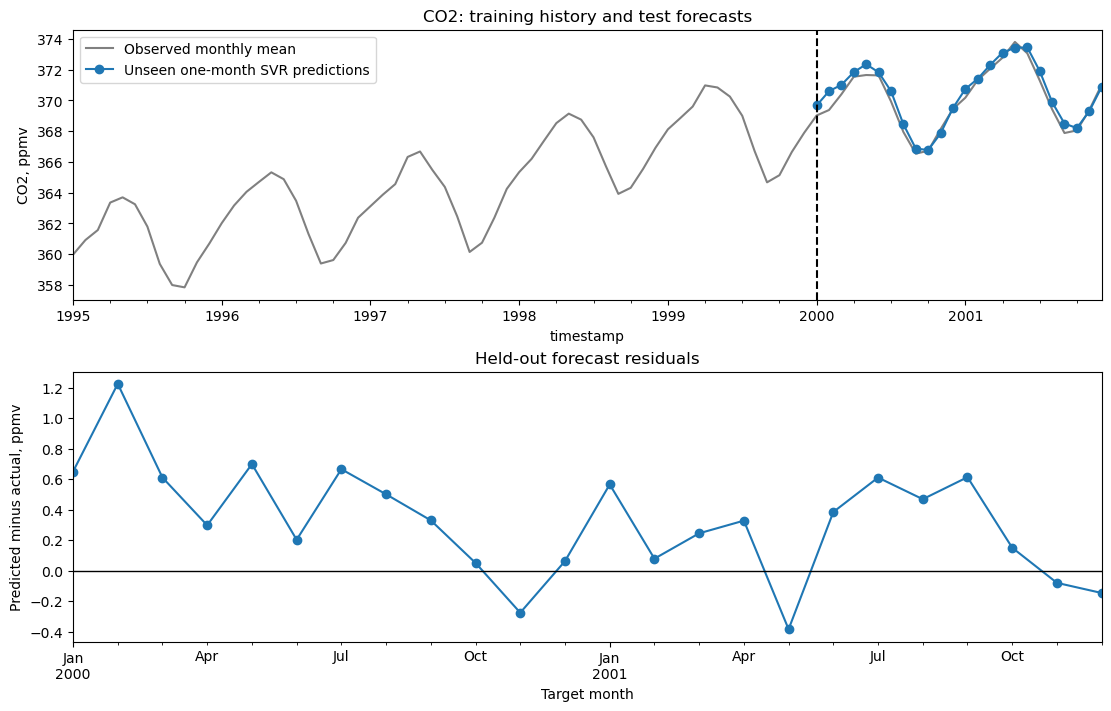

In [4]:
test['seasonal_naive'] = series.shift(12).reindex(test.index)
metrics = pd.DataFrame([
    {'method':name,'MAPE_percent':100*mean_absolute_percentage_error(test.target,test[name]),
     'MAE_ppmv':mean_absolute_error(test.target,test[name]),'RMSE_ppmv':root_mean_squared_error(test.target,test[name])}
    for name in ['prediction','persistence','seasonal_naive']
])
assert len(test)==24
display(metrics.round(5))
pd.DataFrame(rows).to_csv('co2-validation.csv',index=False)
metrics.to_csv('co2-metrics.csv',index=False)
test.to_csv('co2-forecasts.csv',index_label='timestamp')
fig, axes = plt.subplots(2,1,figsize=(11,7),layout='constrained')
series.loc['1995':].plot(ax=axes[0],color='grey',label='Observed monthly mean')
test.prediction.plot(ax=axes[0],marker='o',label='Unseen one-month SVR predictions')
axes[0].axvline(pd.Timestamp('2000-01-01'),color='black',linestyle='--')
axes[0].set(title='CO2: training history and test forecasts',ylabel='CO2, ppmv')
axes[0].legend()
(test.prediction-test.target).plot(ax=axes[1],marker='o')
axes[1].axhline(0,color='black',linewidth=1)
axes[1].set(title='Held-out forecast residuals',ylabel='Predicted minus actual, ppmv',xlabel='Target month')
fig.savefig('svr-co2.png',dpi=150)
plt.show()

## Interpretation

The saved tables expose every parameter/lookback experiment and the chosen
model's test accuracy. Linear and RBF kernels behave differently as levels
rise beyond the training range. The large positive CO2 level makes even a
weak forecast's percentage error small, so compare MAE in ppmv and the
persistence baseline too. Lagged test observations are revealed one month
at a time, matching a rolling forecast, not a fixed twenty-four-month
forecast. A short historical holdout cannot establish present climate or
sensor-monitoring performance.